<a href="https://colab.research.google.com/github/arcalex/WACAD/blob/main/notebooks/exp-02_WebArchive_Working_With_WARCs_Ext.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Working with WARC Files


## Overview

This notebook demonstrates how to query and extract web archive data from WARC files using a CDX index. It provides a foundation for working with raw web archive data and accompanying index files.

This notebook uses existing WARC files with pre-generated CDX files, located in an S3 bucket. This S3 bucket has been periodically made public for the use of this notebook in workshops. If the S3 bucket is not longer publically accessible, then this notebook can be reconfigured to point at an alternative endpoint with WARC and CDX data.

Note, some of the code cells contain commented out code for loading CDX and WARC data from local files. To use this, uncomment it, and comment out the equivalent S3 code. This scenario works when running the Jupyter Notebook in a local environment on your device.

### Learning Objectives

1. Understand the roles of WARC and CDX files in web archiving
2. Load and interpret CDX index files
3. Find archived records in WARC files using index metadata
4. Extract textual content from archived web pages

This notebook serves as an introduction to web archive access methods that will be built upon in subsequent notebooks.

## Environment Setup

### Installing Required Python Packages

The following packages are necessary for working with web archives:

In [ ]:
!pip install boto3 s3fs pandas warcio beautifulsoup4 trafilatura

In [ ]:
import pandas as pd
import requests
import re
import spacy
import matplotlib.pyplot as plt
import boto3                                        #Connects to Amazon S3
import trafilatura                                  #Extracts article text from HTML
from bs4 import BeautifulSoup                       #Parses HTML content
from warcio.archiveiterator import ArchiveIterator  #Reads WARC records
from botocore.client import Config
from transformers import pipeline
from collections import Counter
from getpass import getpass
from difflib import SequenceMatcher

### 1. Accessing WARC Files

WARC (Web ARChive) files are the standard format for storing web archives. They contain the actual content of archived web pages along with metadata. In this section, we'll explore how to access,list and extract data from WARC files.

> ***Note***
>
> *This section is using a dataset extracted from Common Crawl web archive (CC-NEWS). To ensure accessibility and simulate cloud storage, we have hosted these WARC and CDX files in a local MinIO S3-compatible bucket for the purposes of this workshop*

In [ ]:
URL = input("URL: ")
USERNAME = input("Username: ")
PASSWORD = getpass("Password: ")

In [ ]:
bucket_name = 'warc-data'
cdx_files = []

#Define S3 bucket
s3 = boto3.client(
    's3',
    endpoint_url= URL,
    aws_access_key_id= USERNAME,
    aws_secret_access_key= PASSWORD,
    config=Config(signature_version='s3v4')
)

#Return a dictionary containing the bucket's metadata
response = s3.list_objects_v2(Bucket=bucket_name)
all_files = response.get('Contents', [])

print("Files in bucket:")
for file in all_files:
  print(file['Key'])

### Understanding CDX Files

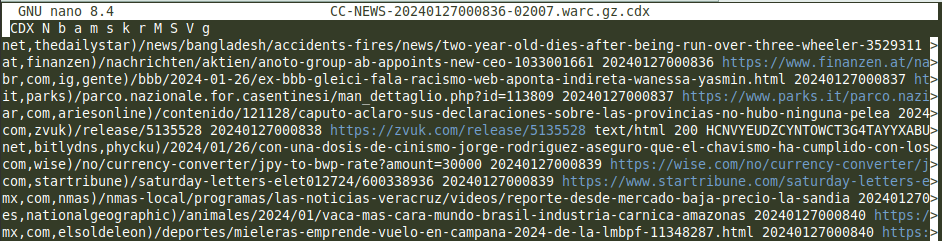

CDX (Capture inDeX) files serve as indexes for WARC files, making it easier to locate specific content. They follow a standardized format described in the [CDX documentation](https://iipc.github.io/warc-specifications/specifications/cdx-format/cdx-2015/).

The standard 11-field CDX format includes:

1. **N**: Normalized/massaged URL
2. **b**: Capture date (timestamp)
3. **a**: Original URL
4. **m**: MIME type of the document
5. **s**: HTTP response code
6. **k**: Content checksum
7. **r**: Redirect URL
8. **M**: Meta tags
9. **S**: Compressed record size
10. **V**: Compressed payload offset
11. **g**: Source WARC filename

Let's load a CDX file and examine its structure:

In [ ]:
cdx_file = 'CC-NEWS-20240127000836-02007.warc.gz.cdx'

df = pd.read_csv(f"s3://{bucket_name}/{cdx_file}", sep=" ", skiprows=1, storage_options={
        "key":            USERNAME,
        "secret":         PASSWORD,
        "client_kwargs":  {"endpoint_url": URL},
    })

#Assign column names according to the CDX standard
df.columns = ["N", "b", "a", "m", "s", "k", "r", "M", "S", "V", "g"]

display(df)

### 2. Extracting Content from WARC Files

Using the information from the CDX file (particularly the filename and offset), we can extract html content from a WARC file in S3 bucket using a specific offset.


In [ ]:
warc_file = 'CC-NEWS-20240127000836-02007.warc.gz'
offset, size = 640127169, 44155

#Get record metadata from S3 bucket
response = s3.get_object(
    Bucket=bucket_name,
    Key=warc_file,
    Range=f"bytes={offset}-{offset+size-1}"
)

#Decompress, read WARC Headers and return response
record = next(item for item in ArchiveIterator(response["Body"]) if item.rec_type == 'response')

#Bypass html headers and decode to text
html_payload = record.content_stream().read().decode('utf-8', errors='replace')

#### Extracting Webpage Metadata and Copyright Information

In [ ]:
page = BeautifulSoup(html_payload, "html.parser")

for tag in page.find_all("meta"):
    key = tag.get("name") or tag.get("property") or ""
    if re.search("author|copyright|license|publish|date", key, re.I): print(key, "->", tag.get("content"))

print("License links:", [l.get("href") for l in page.find_all(["link", "a"], rel=lambda r: r and "license" in r)])
print("Structured data:", re.findall(r'"(?:author|copyrightHolder|license)"\s*:\s*[^,]{0,60}', html_payload)[:4])
print("Visible notice:", re.findall(r"(?:Copyright|©)[^.]{0,80}", page.get_text(" ", strip=True))[:2])

#### Detecting Content Rot in Archived Webpages



In [ ]:
from difflib import SequenceMatcher
import requests
import trafilatura

url = record.rec_headers.get_header("WARC-Target-URI")
live = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=10)

arch_txt = (trafilatura.extract(html_payload) or "").split()
live_txt = (trafilatura.extract(live.text) or "").split() if live.ok else []

sim = SequenceMatcher(None, arch_txt, live_txt).ratio()
status = "Intact" if sim > 0.8 else "Drifted" if sim > 0.2 else "Content Rot / Lost"

print(f"Live Page HTTP Status: {live.status_code}")
print(f"Content Retained:      {sim:.1%}")

## 3. Processing and Analyzing Web Archive Content

Once we've extracted content from WARC files, we can process and analyze it using various tools. For HTML content, the *BeautifulSoup* Python library is particularly useful for parsing and extracting text.

In [ ]:
all_text = trafilatura.extract(html_payload, include_comments=False, include_tables=False) or ""

#### Named Entity Recognition and Frequency Visualization


In [ ]:
#Extract Entities
nlp = spacy.load("en_core_web_sm")
doc = nlp(all_text)
entities = [ent.text for ent in doc.ents if ent.label_ in ["PERSON", "ORG", "GPE"]]

top_entities = Counter(entities).most_common(8)
labels, values = zip(*top_entities)
plt.barh(labels, values, color='skyblue')
plt.title("Key Entities Mentioned in the Article")
plt.show()

#### Zero-Shot Classification (Dynamic Topic & Sentiment Analysis)

In [ ]:
#Load the superior DeBERTa model
classifier = pipeline("zero-shot-classification", model="MoritzLaurer/deberta-v3-base-zeroshot-v2.0")

#Define your labels
sentiment_labels = ["positive", "negative", "neutral"]
topic_labels = ["science", "politics", "technology", "health", "business", "sports"]
short_text = all_text[:600]

#Run Inference
sent_result = classifier(short_text, candidate_labels=sentiment_labels, hypothesis_template="This text is {}.", truncation=True)
topic_result = classifier(short_text, candidate_labels=topic_labels, hypothesis_template="This article is about {}.", truncation=True)

print(" AI Sentiment Analysis")
for label, score in zip(sent_result['labels'][:1], sent_result['scores']):
    print(f" - {label.upper():<10} : {score*100:.1f}%")

print("\n AI Topic Classification ")
for label, score in zip(topic_result['labels'][:2], topic_result['scores']):
    print(f" - {label.upper():<10} : {score*100:.1f}%")

### Citation

**Title:** Working with WARC Files (Jupyter notebook)  
**Author:** Yizhe Zhan, Ben O'Brien  
**Affiliation:** National Library of New Zealand, Wellington  
**Last updated:** 2026‑04‑14  

**Contact:** yizhe.git@gmail.com  
**Repository:** https://github.com/NLNZDigitalPreservation/wa-nlnz-toolkit